## <div align="center"> TUGAS LAB IS388 Data Analysis </div>
## <div align="center"> WEEK [06]: [Data Visualization]</div>
#### <div align="center"> Semester Ganjil 2024/2025 </div>
---

In [15]:
import datetime
import uuid

studentName = "Joyandro Gerard Diasz"
studentNIM = "00000158474"
studentClass = "B"

In [16]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("NIM: \t\t{}".format(studentClass))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Joyandro Gerard Diasz
NIM: 		00000158474
NIM: 		B
Start: 		2026-09-29 14:18:05.438772
Device ID: 	ea0da9a5-bbd5-11f1-be09-24b2b965c072


---

## <div align="center"> Unguided Lab </div>

### Enter Unguided Lab Code Here:

In [17]:
from io import StringIO
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid")

## <div align="center"> Question 01 </div>

In [18]:
# Dataset dapat dibuka dari folder Week_06 atau dari root proyek.
possible_paths = [
    Path("sales_adidas.csv"),
    Path("Week_06") / "sales_adidas.csv",
]
dataset_path = next((path for path in possible_paths if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError("sales_adidas.csv tidak ditemukan.")

adidas_data = pd.read_csv(dataset_path)

info_buffer = StringIO()
adidas_data.info(buf=info_buffer)

print("Dataset:", dataset_path)
print("Bentuk dataset:", adidas_data.shape)
print()
print("Informasi dataset:")
print(info_buffer.getvalue())
print("Deskripsi dataset:")
display(adidas_data.describe(include="all").T)
print("Lima baris pertama:")
display(adidas_data.head())

Dataset: sales_adidas.csv
Bentuk dataset: (9641, 12)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9641 entries, 0 to 9640
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Retailer          9641 non-null   object
 1   Retailer ID       9641 non-null   int64 
 2   Invoice Date      9641 non-null   object
 3   Region            9641 non-null   object
 4   State             9641 non-null   object
 5   City              9641 non-null   object
 6   Product           9641 non-null   object
 7   Price per Unit    9641 non-null   int64 
 8   Units Sold        9641 non-null   int64 
 9   Total Sales       9641 non-null   int64 
 10  Operating Profit  9641 non-null   int64 
 11  Sales Method      9641 non-null   object
dtypes: int64(5), object(7)
memory usage: 904.0+ KB

Deskripsi dataset:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Retailer,9641,6,Foot Locker,2634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Retailer ID,9641.0,NaN,NaN,NaN,1173850.500674,26358.686233,1128299.0,1185732.0,1185732.0,1185732.0,1197831.0
Invoice Date,9641,724,1/17/2021,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,9641,5,West,2446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,9641,50,Texas,430,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9641,52,Portland,360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,9641,6,Men's Street Footwear,1610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price per Unit,9641.0,NaN,NaN,NaN,45.20278,14.717896,0.0,35.0,45.0,55.0,110.0
Units Sold,9641.0,NaN,NaN,NaN,256.779483,214.117101,0.0,106.0,176.0,350.0,1275.0
Total Sales,9641.0,NaN,NaN,NaN,9316.467898,14182.917947,0.0,425.0,957.0,15000.0,82500.0


Lima baris pertama:


,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Sales Method
0,Walmart,1128299,6/17/2021,Southeast,Florida,Orlando,Women's Apparel,103,218,2245,1257,Online
1,West Gear,1128299,7/16/2021,South,Louisiana,New Orleans,Women's Apparel,103,163,1679,806,Online
2,Sports Direct,1197831,8/25/2021,South,Alabama,Birmingham,Men's Street Footwear,10,700,7000,3150,Outlet
3,Sports Direct,1197831,8/27/2021,South,Alabama,Birmingham,Women's Street Footwear,15,575,8625,3881,Outlet
4,Sports Direct,1197831,8/21/2021,South,Alabama,Birmingham,Women's Street Footwear,15,475,7125,3206,Outlet


## <div align="center"> Question 02 </div>

,Product,Total Sales
2,Men's Street Footwear,20882669
3,Women's Apparel,17847910
1,Men's Athletic Footwear,15322410
5,Women's Street Footwear,12770688
0,Men's Apparel,12337155
4,Women's Athletic Footwear,10659235


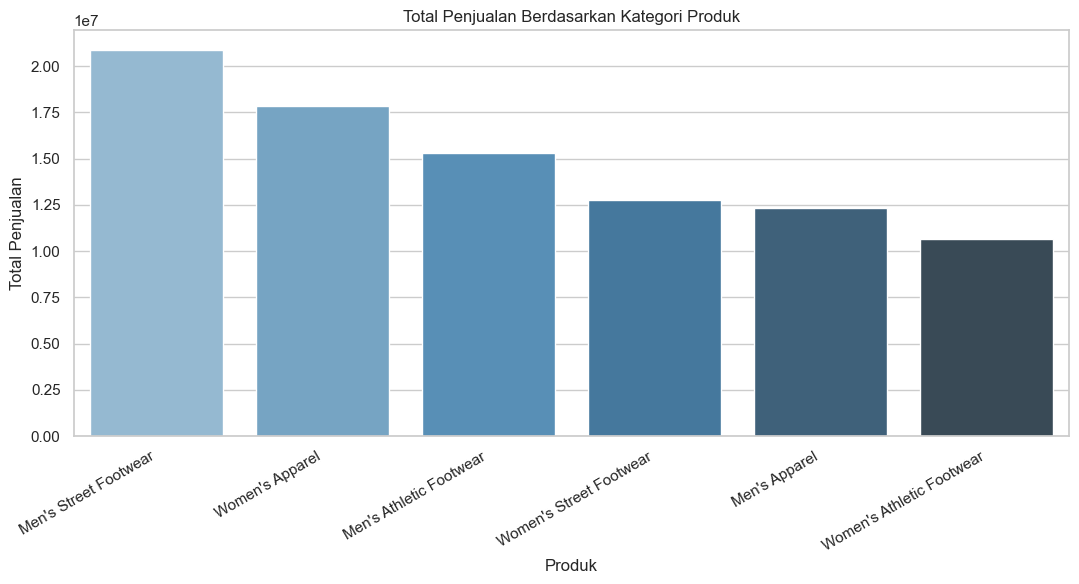

Produk dengan total penjualan terbesar adalah Men's Street Footwear sebesar 20,882,669.


In [19]:
# Menghitung total penjualan untuk setiap kategori produk.
sales_by_product = (
    adidas_data.groupby("Product", as_index=False)["Total Sales"]
    .sum()
    .sort_values("Total Sales", ascending=False)
)

display(sales_by_product)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=sales_by_product,
    x="Product",
    y="Total Sales",
    hue="Product",
    palette="Blues_d",
    legend=False,
)
plt.title("Total Penjualan Berdasarkan Kategori Produk")
plt.xlabel("Produk")
plt.ylabel("Total Penjualan")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

top_product = sales_by_product.iloc[0]
print(
    f"Produk dengan total penjualan terbesar adalah {top_product['Product']} "
    f"sebesar {top_product['Total Sales']:,}."
)

## <div align="center"> Question 03 </div>

,Jumlah,Persentase (%)
Retailer,,
Foot Locker,2634,27.32
West Gear,2372,24.60
Sports Direct,2030,21.06
Kohl's,1030,10.68
Amazon,949,9.84
Walmart,626,6.49


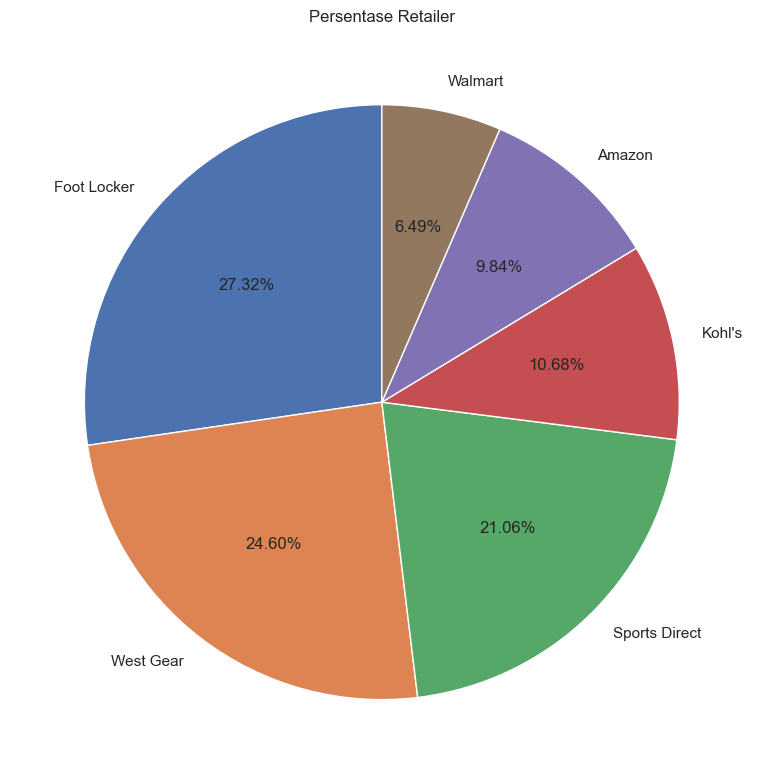

Retailer dengan proporsi terbesar adalah Foot Locker sebesar 27.32%.


In [20]:
# Menghitung persentase kemunculan setiap retailer.
retailer_counts = adidas_data["Retailer"].value_counts()
retailer_percentages = (
    adidas_data["Retailer"].value_counts(normalize=True).mul(100).round(2)
)

display(
    pd.DataFrame(
        {
            "Jumlah": retailer_counts,
            "Persentase (%)": retailer_percentages,
        }
    )
)

plt.figure(figsize=(8, 8))
plt.pie(
    retailer_counts.values,
    labels=retailer_counts.index,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
)
plt.title("Persentase Retailer")
plt.tight_layout()
plt.show()

print(
    f"Retailer dengan proporsi terbesar adalah {retailer_counts.index[0]} "
    f"sebesar {retailer_percentages.iloc[0]:.2f}%."
)

## <div align="center"> Question 04 </div>

,Invoice Date,Total Sales
0,2020-01-01,1625381
1,2020-02-01,1499801
2,2020-03-01,1766062
3,2020-04-01,2460705
4,2020-05-01,1691806
5,2020-06-01,882984
6,2020-07-01,1690979
7,2020-08-01,1952802
8,2020-09-01,1830446
9,2020-10-01,1083626


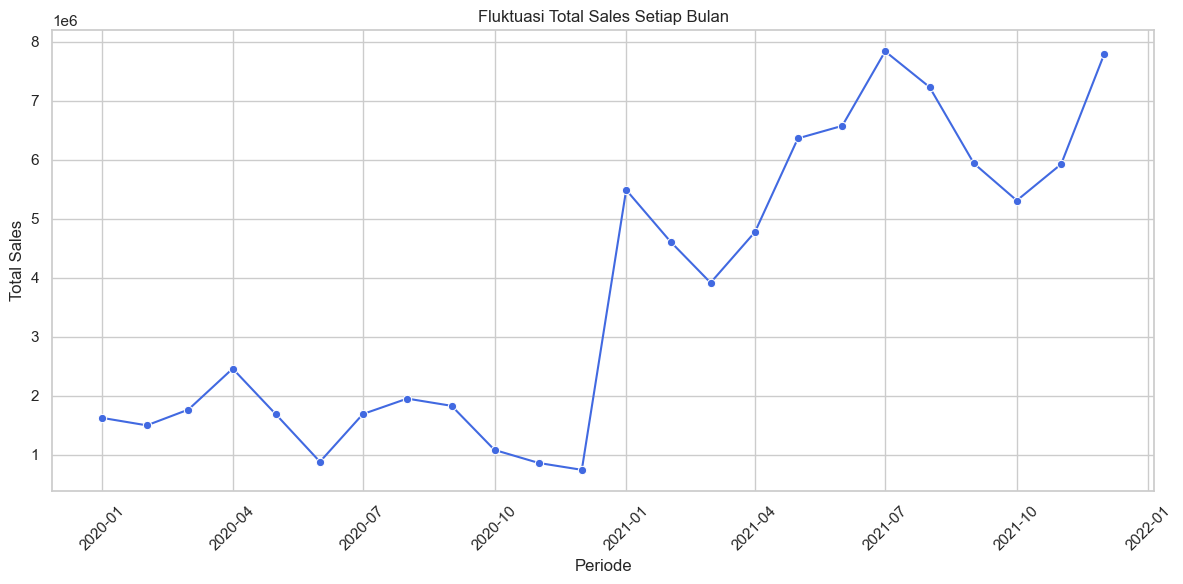

Penjualan bulanan tertinggi terjadi pada July 2021 sebesar 7,833,488.


In [21]:
# Mengubah tanggal dan mengagregasi Total Sales per bulan.
adidas_data["Invoice Date"] = pd.to_datetime(
    adidas_data["Invoice Date"],
    format="mixed",
)
monthly_sales = (
    adidas_data.groupby(adidas_data["Invoice Date"].dt.to_period("M"))["Total Sales"]
    .sum()
    .reset_index()
)
monthly_sales["Invoice Date"] = monthly_sales["Invoice Date"].dt.to_timestamp()

display(monthly_sales)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_sales,
    x="Invoice Date",
    y="Total Sales",
    marker="o",
    color="royalblue",
)
plt.title("Fluktuasi Total Sales Setiap Bulan")
plt.xlabel("Periode")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

peak_month = monthly_sales.loc[monthly_sales["Total Sales"].idxmax()]
print(
    f"Penjualan bulanan tertinggi terjadi pada "
    f"{peak_month['Invoice Date']:%B %Y} sebesar {peak_month['Total Sales']:,}."
)

## <div align="center"> Question 05 </div>

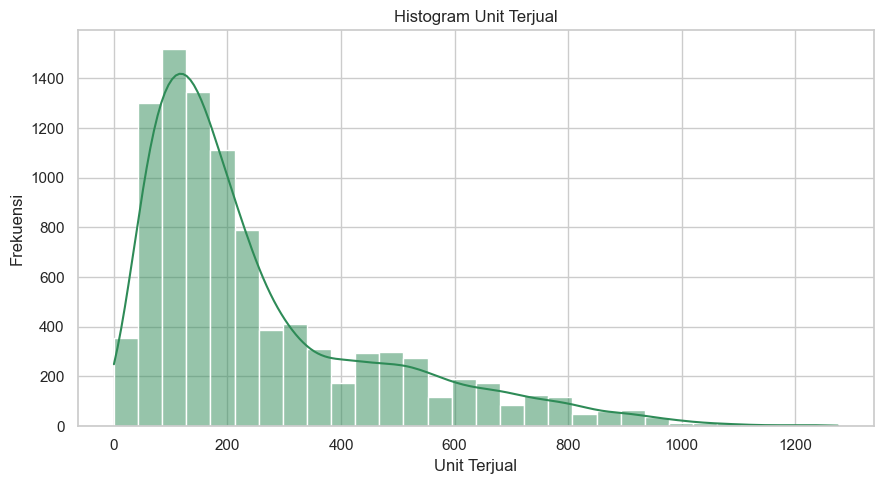

Skewness Units Sold: 1.464
Distribusi Units Sold condong ke kanan karena skewness bernilai positif.


In [22]:
# Menampilkan distribusi Units Sold dengan density curve.
units_skewness = adidas_data["Units Sold"].skew()

plt.figure(figsize=(9, 5))
sns.histplot(
    data=adidas_data,
    x="Units Sold",
    bins=30,
    kde=True,
    color="seagreen",
)
plt.title("Histogram Unit Terjual")
plt.xlabel("Unit Terjual")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

print(f"Skewness Units Sold: {units_skewness:.3f}")
print("Distribusi Units Sold condong ke kanan karena skewness bernilai positif.")

## <div align="center"> Question 06 </div>

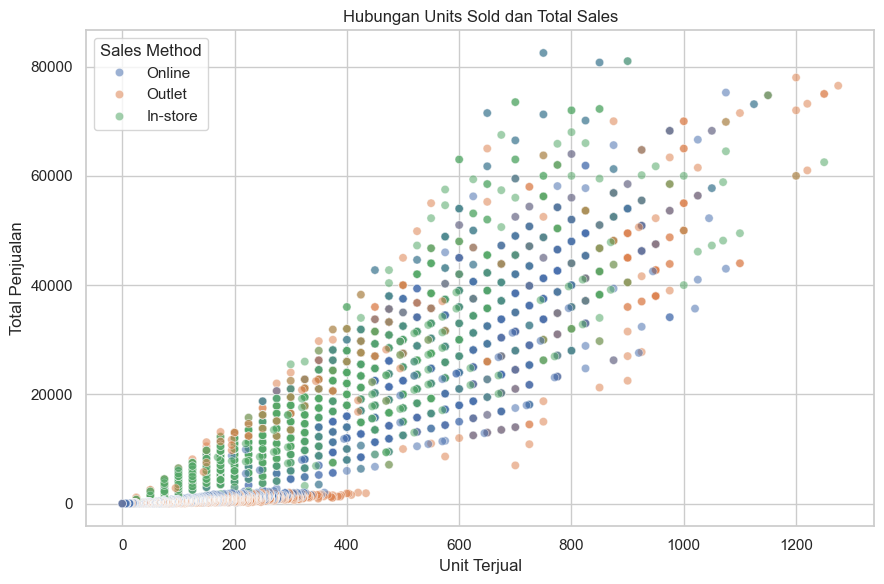

Korelasi Units Sold dan Total Sales: 0.913
Korelasi positif yang kuat menunjukkan penjualan cenderung meningkat saat unit terjual bertambah.


In [23]:
# Scatter plot membutuhkan dua variabel; digunakan Units Sold dan Total Sales.
units_sales_correlation = adidas_data["Units Sold"].corr(
    adidas_data["Total Sales"]
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=adidas_data,
    x="Units Sold",
    y="Total Sales",
    hue="Sales Method",
    alpha=0.55,
)
plt.title("Hubungan Units Sold dan Total Sales")
plt.xlabel("Unit Terjual")
plt.ylabel("Total Penjualan")
plt.tight_layout()
plt.show()

print(f"Korelasi Units Sold dan Total Sales: {units_sales_correlation:.3f}")
print("Korelasi positif yang kuat menunjukkan penjualan cenderung meningkat saat unit terjual bertambah.")

## <div align="center"> Question 07 </div>

,Retailer ID,Price per Unit,Units Sold,Total Sales,Operating Profit
Retailer ID,1.000,-0.391,-0.003,-0.083,-0.027
Price per Unit,-0.391,1.000,0.264,0.434,0.393
Units Sold,-0.003,0.264,1.000,0.913,0.893
Total Sales,-0.083,0.434,0.913,1.000,0.957
Operating Profit,-0.027,0.393,0.893,0.957,1.000


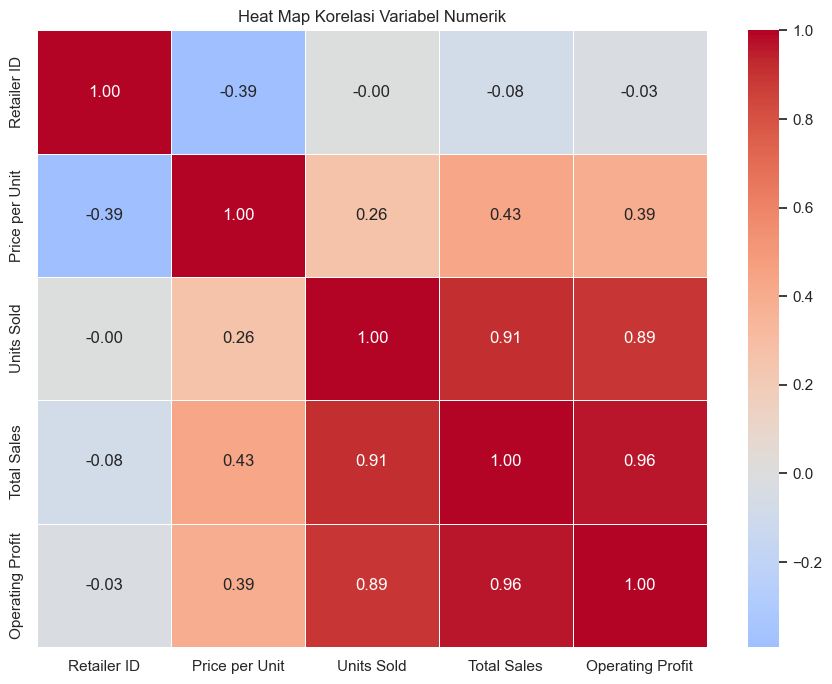

Korelasi tertinggi terlihat antara Total Sales dan Operating Profit, serta antara Units Sold dan Total Sales.


In [24]:
# Memilih kolom numerik dan menghitung matriks korelasi.
numeric_data = adidas_data.select_dtypes(include="number")
correlation_matrix = numeric_data.corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)
plt.title("Heat Map Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

print(
    "Korelasi tertinggi terlihat antara Total Sales dan Operating Profit, "
    "serta antara Units Sold dan Total Sales."
)

## <div align="center"> Question 08 </div>

Jumlah missing values per kolom:


,Missing Values
Retailer,0
Retailer ID,0
Invoice Date,0
Region,0
State,0
City,0
Product,0
Price per Unit,0
Units Sold,0
Total Sales,0


Total missing values: 0


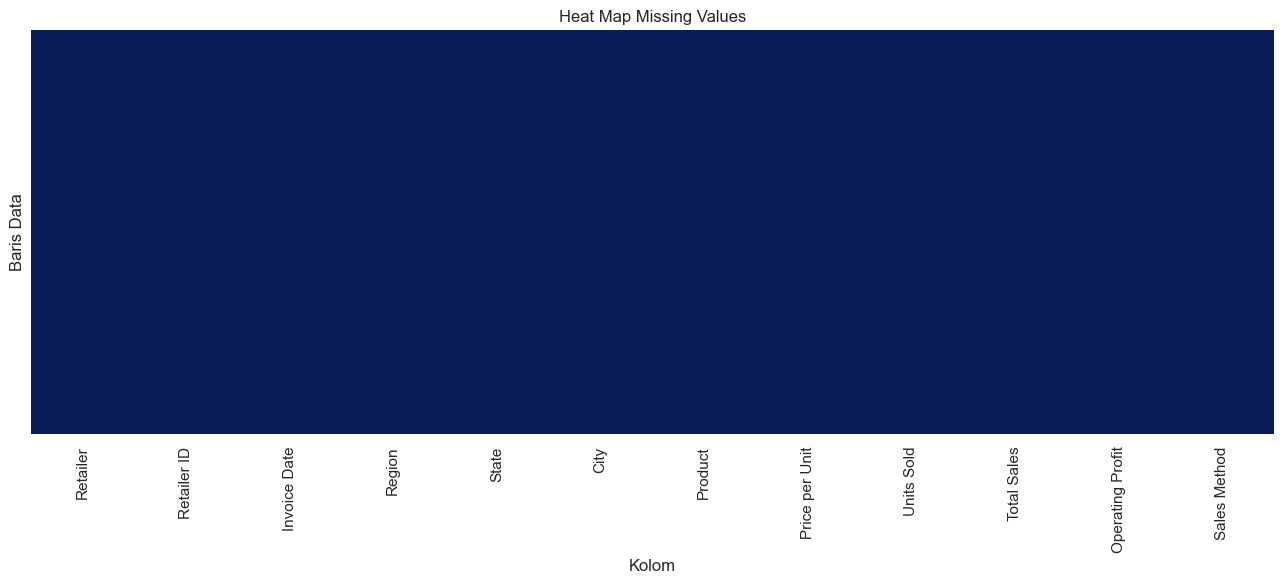

Heat map tidak menunjukkan sel kosong karena dataset tidak memiliki missing values.


In [25]:
# Menampilkan lokasi missing values pada seluruh DataFrame.
missing_per_column = adidas_data.isna().sum()
print("Jumlah missing values per kolom:")
display(missing_per_column.to_frame(name="Missing Values"))
print("Total missing values:", int(missing_per_column.sum()))

plt.figure(figsize=(13, 6))
sns.heatmap(
    adidas_data.isna(),
    cbar=False,
    yticklabels=False,
    cmap="YlGnBu_r",
)
plt.title("Heat Map Missing Values")
plt.xlabel("Kolom")
plt.ylabel("Baris Data")
plt.tight_layout()
plt.show()

print("Heat map tidak menunjukkan sel kosong karena dataset tidak memiliki missing values.")

----

## <div align="center"> Conclusion </div>

### Kesimpulan

Dataset `sales_adidas.csv` berisi 9.641 baris dan 12 kolom tanpa missing value. Produk dengan total penjualan terbesar adalah **Men's Street Footwear** dengan total 20.882.669, sedangkan **Foot Locker** memiliki proporsi transaksi terbesar sebesar 27,32%. Penjualan bulanan tertinggi terjadi pada Juli 2021 dengan total 7.833.488.

Distribusi `Units Sold` condong ke kanan. Hubungan `Units Sold` dan `Total Sales` sangat kuat dan positif dengan korelasi sekitar 0,913. Heat map juga menunjukkan hubungan yang sangat kuat antara `Total Sales` dan `Operating Profit`.

----

In [26]:
studentName2 = "Nama2"
studentNIM2 = "NIM2"
studentClass2 = "Class2"

In [27]:
print("Name: \t\t{}".format(studentName2))
print("NIM: \t\t{}".format(studentNIM2))
print("NIM: \t\t{}".format(studentClass2))
print("End: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Nama2
NIM: 		NIM2
NIM: 		Class2
End: 		2026-09-29 14:18:05.438772
Device ID: 	ea0da9a5-bbd5-11f1-be09-24b2b965c072


----

## <div align="center"> Reference </div>

----